### 1. Load libraries

In [6]:
import sys
import os
import numpy as np
import polars as pl
import seaborn as sns
import matplotlib.pyplot as plt

### 2. Analysis of raw experimental data

In [10]:
sys.path.append(os.path.abspath("../processing"))

In [12]:
from experimental_data_preprocessing import ExperimentalValidation

In [42]:
thresholds = [0.05, 0.1, 0.15, 0.20, 0.25, 0.30, 0.35, 0.40, 0.45, 0.5, 0.55, 0.65, 0.70, 0.75]
lengths = []
for i in thresholds:
    validated_data = ExperimentalValidation(path_to_data=r'D:\Juan\proyectos_personales\Maestría\Materias\Tesis\oleosim\OLEOSIM_Thermodynamics\Unifac_Dortmund\Experimental_Data\data\raw_lle_data.xlsx', 
                                            component_list=['FAME/FAEE', 'GLYCEROL', 'ALCOHOL', 'OIL', 'DAG', 'MAG', 'ACID', 'WATER'], 
                                            column_list_to_remove=['Ref', 'Sub Ref', 'Temperature (K)', 'Type Alcohol'],
                                            error_threshold=i).validate_data()
    lengths.append(validated_data.shape[0])
    
    

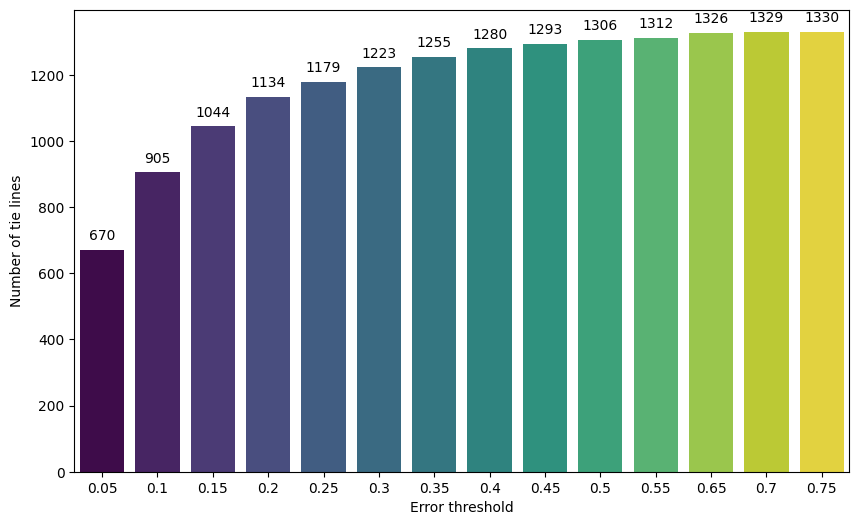

In [56]:
plt.figure(figsize=(10, 6))
ax = sns.barplot(x=thresholds, y=lengths, palette='viridis', hue=thresholds, legend=False)

# Annotate the bars with the values
for p in ax.patches:
    ax.annotate(f'{p.get_height():.0f}', 
                (p.get_x() + p.get_width() / 2., p.get_height()), 
                ha='center', va='center', 
                xytext=(0, 10), 
                textcoords='offset points')

# Set labels and title
ax.set_xlabel('Error threshold')
ax.set_ylabel('Number of tie lines')

# Show the plot
plt.show()

In [23]:
raw_data = (pl.read_excel(r'D:\Juan\proyectos_personales\Maestría\Materias\Tesis\oleosim\OLEOSIM_Thermodynamics\Unifac_Dortmund\Experimental_Data\data\raw_lle_data.xlsx', engine='calamine'))
